In [1]:
pip install -U transformers torchvision scikit-learn pillow tqdm

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.1/13.1 MB 14.9 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 13.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.3/8.3 MB 15.3 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 15.5 MB/s eta 0:00:00a 0:00:01
  Attempting uninstall: pillow
    Found existing installation: pillow 11.1.0
    Uninstalling pillow-11.1.0:
      Successfully uninstalled pillow-11.1.0
  Attempting uninstall: scikit-learn━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1/5 [narwhals]
    Found existing installation: scikit-learn 1.6.1━━━━━━━━━━━ 1/5 [narwhals]
    Uninstalling scikit-learn-1.6.1:━━━━━━━━━━━━━━━━━━━━━━━━━━ 1/5 [narwhals]
      Successfully uninstalled scikit-learn-1.6.1━━━━━━━━━━━━━ 1/5 [narwhals]
  Attempting uninstall: torchvision━━━━━━━━━━━━━━━━━━━━━━━ 2/5 [scikit-learn]
    Found existing installation: torchvision 0.29.0━━━━━━━━━━━ 2/5 [scikit-learn]
    Uninstalling torchvision-0.2

In [2]:
from pathlib import Path
import random 
import numpy as np
import torch 
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset
from torchvision.datasets import ImageFolder
from PIL import Image
from tqdm import tqdm
from sklearn.metrics import accuracy_score, f1_score, classification_report

from transformers import pipeline, ViTImageProcessor, ViTForImageClassification, get_linear_schedule_with_warmup


# ---- paths / protocol settings ----
CLEAN_DIR = Path("/Users/aficca/Documents/stor566_proj/archive_clean")
OUT_DIR = Path("/Users/aficca/Documents/stor566_proj/vit_results")
OUT_DIR.mkdir(parents=True, exist_ok=True)
MODEL_NAME = "google/vit-base-patch16-224"
NUM_CLASSES = 7
BATCH_SIZE = 32
NUM_EPOCHS = 5          # raise later if needed
LR = 2e-5
SEED = 42
# noise-aug training (RQ3) — tune on val later
NOISE_AUG_PROB = 0.5
NOISE_AUG_SIGMA = 0.2
# evaluation noise levels (same idea as your CNN notebook)
NOISE_LEVELS = (0.0, 0.1, 0.2, 0.3, 0.4, 0.5)
device = torch.device(
    "mps" if torch.backends.mps.is_available()
    else "cuda" if torch.cuda.is_available()
    else "cpu"
)
print("device:", device)
def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
set_seed(SEED)

W1110 18:12:14.859000 72498 site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


device: mps


In [3]:
processor = ViTImageProcessor.from_pretrained(MODEL_NAME)

class FERViTDataset(Dataset):
    """
    ImageFolder wrapper for ViT.
    Optional Gaussian noise is applied on [0,1] pixels before ViT preprocessing.
    """
    def __init__(self, root, processor, train_noise=False,
                 noise_prob=0.0, noise_sigma=0.0, seed=42):
        self.base = ImageFolder(root)
        self.processor = processor
        self.train_noise = train_noise
        self.noise_prob = noise_prob
        self.noise_sigma = noise_sigma
        self.rng = np.random.default_rng(seed)
        self.classes = self.base.classes
        self.class_to_idx = self.base.class_to_idx

    def __len__(self):
        return len(self.base)

    def __getitem__(self, idx):
        img, label = self.base[idx]          # PIL image
        img = img.convert("L")               # grayscale FER
        arr = np.asarray(img, dtype=np.float32) / 255.0   # [0,1]

        if self.train_noise and self.rng.random() < self.noise_prob:
            noise = self.rng.normal(0.0, self.noise_sigma, size=arr.shape).astype(np.float32)
            arr = np.clip(arr + noise, 0.0, 1.0)

        # grayscale -> 3-channel uint8 for the processor
        arr3 = np.stack([arr, arr, arr], axis=-1)                 # HWC
        arr3 = (arr3 * 255.0).round().astype(np.uint8)
        pil_rgb = Image.fromarray(arr3, mode="RGB")

        inputs = self.processor(images=pil_rgb, return_tensors="pt")
        pixel_values = inputs["pixel_values"].squeeze(0)          # [3,224,224]
        return pixel_values, label

In [4]:
train_clean = FERViTDataset(CLEAN_DIR / "train", processor, train_noise=False)
val_clean   = FERViTDataset(CLEAN_DIR / "validation", processor, train_noise=False)
test_clean  = FERViTDataset(CLEAN_DIR / "test", processor, train_noise=False)

print("classes:", train_clean.classes)
print("n train/val/test:", len(train_clean), len(val_clean), len(test_clean))

train_loader = DataLoader(train_clean, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
val_loader   = DataLoader(val_clean,   batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader  = DataLoader(test_clean,  batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

classes: ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']
n train/val/test: 27418 3291 3268


In [5]:
id2label = {i: c for i, c in enumerate(train_clean.classes)}
label2id = {c: i for i, c in id2label.items()}

model = ViTForImageClassification.from_pretrained(
    MODEL_NAME,
    num_labels=NUM_CLASSES,
    id2label=id2label,
    label2id=label2id,
    ignore_mismatched_sizes=True,   # replace ImageNet head with 7-class head
).to(device)

print(model.config.num_labels)

[transformers] You passed `num_labels=7` which is incompatible to the `id2label` map of length `1000`.
Loading weights: 100%|██████████| 200/200 [00:00<00:00, 42016.57it/s]
[transformers] ViTForImageClassification LOAD REPORT from: google/vit-base-patch16-224
Key               | Status   |                                                                                          
------------------+----------+------------------------------------------------------------------------------------------
classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000, 768]) vs model:torch.Size([7, 768])
classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000]) vs model:torch.Size([7])          

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


7


In [6]:
criterion = nn.CrossEntropyLoss()

def run_epoch(model, loader, optimizer=None, scheduler=None):
    train_mode = optimizer is not None
    model.train() if train_mode else model.eval()

    total_loss, all_preds, all_labels = 0.0, [], []
    context = torch.enable_grad() if train_mode else torch.no_grad()

    with context:
        for pixel_values, labels in tqdm(loader, leave=False):
            pixel_values = pixel_values.to(device)
            labels = labels.to(device)

            outputs = model(pixel_values=pixel_values)
            loss = criterion(outputs.logits, labels)

            if train_mode:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
                if scheduler is not None:
                    scheduler.step()

            total_loss += loss.item() * labels.size(0)
            preds = outputs.logits.argmax(dim=1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    acc = accuracy_score(all_labels, all_preds)
    macro_f1 = f1_score(all_labels, all_preds, average="macro", zero_division=0)
    avg_loss = total_loss / len(loader.dataset)
    return avg_loss, acc, macro_f1, all_labels, all_preds


def train_vit(model, train_loader, val_loader, save_path, epochs=NUM_EPOCHS, lr=LR):
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.01)
    total_steps = epochs * len(train_loader)
    scheduler = get_linear_schedule_with_warmup(
        optimizer,
        num_warmup_steps=int(0.1 * total_steps),
        num_training_steps=total_steps,
    )

    best_val = -1.0
    history = []

    for epoch in range(1, epochs + 1):
        tr_loss, tr_acc, tr_f1, _, _ = run_epoch(model, train_loader, optimizer, scheduler)
        va_loss, va_acc, va_f1, _, _ = run_epoch(model, val_loader)

        history.append((epoch, tr_loss, tr_acc, tr_f1, va_loss, va_acc, va_f1))
        print(
            f"epoch {epoch}: "
            f"train loss={tr_loss:.4f} acc={tr_acc:.4f} f1={tr_f1:.4f} | "
            f"val loss={va_loss:.4f} acc={va_acc:.4f} f1={va_f1:.4f}"
        )

        if va_acc > best_val:
            best_val = va_acc
            model.save_pretrained(save_path)
            processor.save_pretrained(save_path)
            print(f"  saved best to {save_path} (val acc={best_val:.4f})")

    return history

In [7]:
set_seed(SEED)
model_clean = ViTForImageClassification.from_pretrained(
    MODEL_NAME,
    num_labels=NUM_CLASSES,
    id2label=id2label,
    label2id=label2id,
    ignore_mismatched_sizes=True,
).to(device)

clean_dir = OUT_DIR / "vit_clean"
history_clean = train_vit(
    model_clean, train_loader, val_loader,
    save_path=clean_dir, epochs=NUM_EPOCHS, lr=LR
)

[transformers] You passed `num_labels=7` which is incompatible to the `id2label` map of length `1000`.
Loading weights: 100%|██████████| 200/200 [00:00<00:00, 10013.14it/s]
[transformers] ViTForImageClassification LOAD REPORT from: google/vit-base-patch16-224
Key               | Status   |                                                                                          
------------------+----------+------------------------------------------------------------------------------------------
classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000, 768]) vs model:torch.Size([7, 768])
classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000]) vs model:torch.Size([7])          

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


epoch 1: train loss=1.2154 acc=0.5368 f1=0.4358 | val loss=0.9793 acc=0.6320 f1=0.5333


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  1.13it/s]


  saved best to /Users/aficca/Documents/stor566_proj/vit_results/vit_clean (val acc=0.6320)


epoch 2: train loss=0.8197 acc=0.6994 f1=0.6351 | val loss=0.9430 acc=0.6521 f1=0.5747


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  1.44it/s]


... (2 outputs left out)

Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  1.38it/s]


  saved best to /Users/aficca/Documents/stor566_proj/vit_results/vit_clean (val acc=0.6782)


epoch 4: train loss=0.4484 acc=0.8567 f1=0.8374 | val loss=0.9335 acc=0.6676 f1=0.6151


epoch 5: train loss=0.3243 acc=0.9096 f1=0.9008 | val loss=0.9542 acc=0.6758 f1=0.6273


In [8]:
model_clean = ViTForImageClassification.from_pretrained(clean_dir).to(device)
te_loss, te_acc, te_f1, y_true, y_pred = run_epoch(model_clean, test_loader)

print(f"CLEAN ViT — test acc={te_acc:.4f}, macro-F1={te_f1:.4f}")
print(classification_report(y_true, y_pred, target_names=train_clean.classes, digits=4))

Loading weights: 100%|██████████| 200/200 [00:00<00:00, 7585.87it/s]
                                                 

CLEAN ViT — test acc=0.6848, macro-F1=0.6228
              precision    recall  f1-score   support

       angry     0.6278    0.5487    0.5856       452
     disgust     0.4118    0.3684    0.3889        38
        fear     0.6307    0.4644    0.5349       478
       happy     0.8753    0.9302    0.9019       845
     neutral     0.6245    0.7450    0.6794       596
         sad     0.5297    0.5759    0.5518       573
    surprise     0.7608    0.6783    0.7172       286

    accuracy                         0.6848      3268
   macro avg     0.6372    0.6158    0.6228      3268
weighted avg     0.6835    0.6848    0.6804      3268



In [9]:
train_noisy = FERViTDataset(
    CLEAN_DIR / "train",
    processor,
    train_noise=True,
    noise_prob=NOISE_AUG_PROB,
    noise_sigma=NOISE_AUG_SIGMA,
    seed=SEED,
)
train_noisy_loader = DataLoader(train_noisy, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)

set_seed(SEED)
model_noise = ViTForImageClassification.from_pretrained(
    MODEL_NAME,
    num_labels=NUM_CLASSES,
    id2label=id2label,
    label2id=label2id,
    ignore_mismatched_sizes=True,
).to(device)

noise_dir = OUT_DIR / "vit_noise_aug"
history_noise = train_vit(
    model_noise, train_noisy_loader, val_loader,
    save_path=noise_dir, epochs=NUM_EPOCHS, lr=LR
)

[transformers] You passed `num_labels=7` which is incompatible to the `id2label` map of length `1000`.
Loading weights: 100%|██████████| 200/200 [00:00<00:00, 7409.65it/s]
[transformers] ViTForImageClassification LOAD REPORT from: google/vit-base-patch16-224
Key               | Status   |                                                                                          
------------------+----------+------------------------------------------------------------------------------------------
classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000, 768]) vs model:torch.Size([7, 768])
classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000]) vs model:torch.Size([7])          

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


epoch 1: train loss=1.4518 acc=0.4349 f1=0.3400 | val loss=1.0297 acc=0.6038 f1=0.4996


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  2.68it/s]


  saved best to /Users/aficca/Documents/stor566_proj/vit_results/vit_noise_aug (val acc=0.6038)


epoch 2: train loss=1.1394 acc=0.5651 f1=0.4778 | val loss=0.9883 acc=0.6247 f1=0.5328


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  1.68it/s]


... (6 outputs left out)

  saved best to /Users/aficca/Documents/stor566_proj/vit_results/vit_noise_aug (val acc=0.6639)


epoch 5: train loss=0.9299 acc=0.6578 f1=0.6065 | val loss=0.9106 acc=0.6694 f1=0.5917


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  2.42it/s]

  saved best to /Users/aficca/Documents/stor566_proj/vit_results/vit_noise_aug (val acc=0.6694)


In [10]:
def make_noisy_loader(sigma, split="test"):
    ds = FERViTDataset(
        CLEAN_DIR / split,
        processor,
        train_noise=True,          # force noise
        noise_prob=1.0,            # every image
        noise_sigma=sigma,
        seed=123,                  # fixed test noise seed
    )
    return DataLoader(ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

def noise_sweep(model, name):
    rows = []
    # clean baseline first
    _, clean_acc, clean_f1, _, _ = run_epoch(model, test_loader)
    print(f"\n{name} clean: acc={clean_acc:.4f}, f1={clean_f1:.4f}")

    for sigma in NOISE_LEVELS:
        loader = make_noisy_loader(sigma, split="test")
        _, acc, f1, _, _ = run_epoch(model, loader)
        rel = acc / clean_acc if clean_acc > 0 else float("nan")
        pp_loss = 100.0 * (clean_acc - acc)
        rows.append((sigma, acc, f1, pp_loss, rel))
        print(
            f"{name} sigma={sigma:.1f} | acc={acc:.4f} f1={f1:.4f} "
            f"pp_loss={pp_loss:.2f} relative={rel:.4f}"
        )
    return rows

model_clean = ViTForImageClassification.from_pretrained(clean_dir).to(device)
model_noise = ViTForImageClassification.from_pretrained(noise_dir).to(device)

rows_clean = noise_sweep(model_clean, "ViT-clean-train")
rows_noise = noise_sweep(model_noise, "ViT-noise-aug-train")

Loading weights: 100%|██████████| 200/200 [00:00<00:00, 3834.70it/s]



ViT-clean-train clean: acc=0.6848, f1=0.6228


ViT-clean-train sigma=0.0 | acc=0.6848 f1=0.6228 pp_loss=0.00 relative=1.0000


ViT-clean-train sigma=0.1 | acc=0.3892 f1=0.3355 pp_loss=29.56 relative=0.5684


ViT-clean-train sigma=0.2 | acc=0.2365 f1=0.1618 pp_loss=44.83 relative=0.3454


ViT-clean-train sigma=0.3 | acc=0.2087 f1=0.1218 pp_loss=47.61 relative=0.3047


... (5 outputs left out)

ViT-noise-aug-train sigma=0.2 | acc=0.5217 f1=0.4514 pp_loss=14.69 relative=0.7803


ViT-noise-aug-train sigma=0.3 | acc=0.4477 f1=0.3674 pp_loss=22.09 relative=0.6696


ViT-noise-aug-train sigma=0.4 | acc=0.3800 f1=0.3143 pp_loss=28.86 relative=0.5684


ViT-noise-aug-train sigma=0.5 | acc=0.3228 f1=0.2685 pp_loss=34.58 relative=0.4828


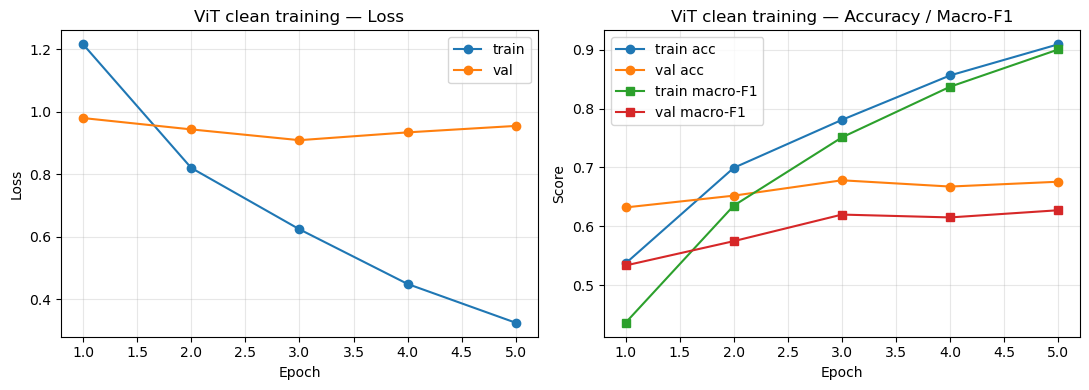

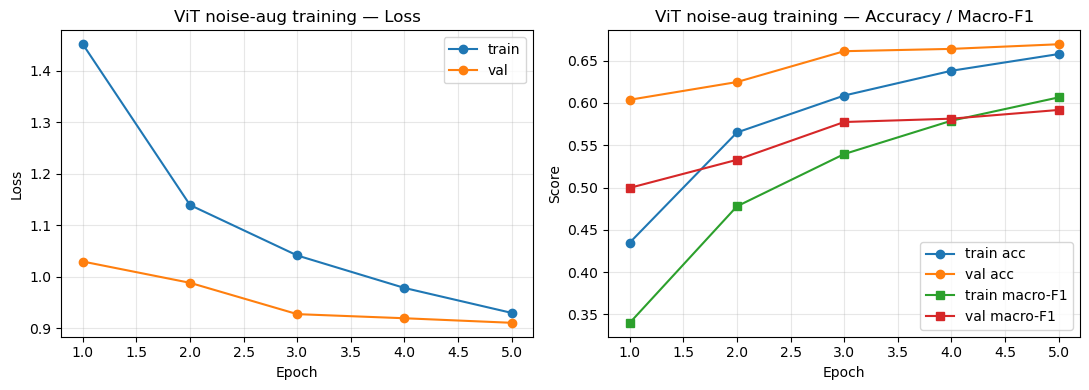

In [11]:
#Evaluation metrics
import matplotlib.pyplot as plt

def plot_history(history, title):
    # history tuples: (epoch, tr_loss, tr_acc, tr_f1, va_loss, va_acc, va_f1)
    epochs = [h[0] for h in history]
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))

    axes[0].plot(epochs, [h[1] for h in history], marker="o", label="train")
    axes[0].plot(epochs, [h[4] for h in history], marker="o", label="val")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Loss")
    axes[0].set_title(f"{title} — Loss")
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)

    axes[1].plot(epochs, [h[2] for h in history], marker="o", label="train acc")
    axes[1].plot(epochs, [h[5] for h in history], marker="o", label="val acc")
    axes[1].plot(epochs, [h[3] for h in history], marker="s", label="train macro-F1")
    axes[1].plot(epochs, [h[6] for h in history], marker="s", label="val macro-F1")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Score")
    axes[1].set_title(f"{title} — Accuracy / Macro-F1")
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

plot_history(history_clean, "ViT clean training")
plot_history(history_noise, "ViT noise-aug training")

Loading weights: 100%|██████████| 200/200 [00:00<00:00, 7207.76it/s]


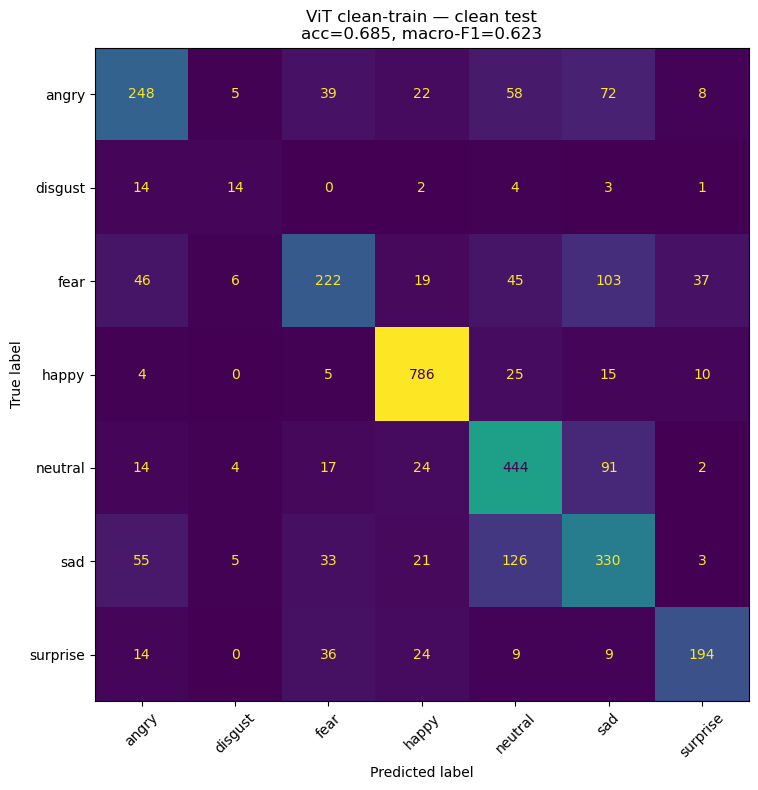

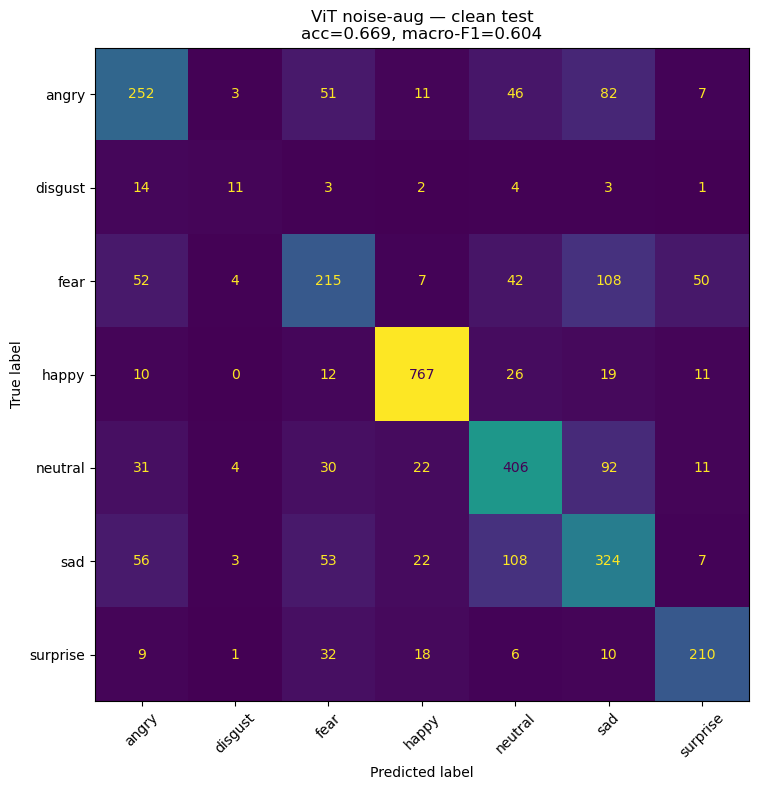

In [12]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

def show_confusion(model, loader, class_names, title, save_name=None):
    _, acc, f1, y_true, y_pred = run_epoch(model, loader)
    cm = confusion_matrix(y_true, y_pred)

    fig, ax = plt.subplots(figsize=(8, 8))
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
    disp.plot(ax=ax, xticks_rotation=45, colorbar=False)
    ax.set_title(f"{title}\nacc={acc:.3f}, macro-F1={f1:.3f}")
    plt.tight_layout()
    if save_name:
        fig.savefig(OUT_DIR / save_name, dpi=200, bbox_inches="tight")
    plt.show()

model_clean = ViTForImageClassification.from_pretrained(clean_dir).to(device)
model_noise = ViTForImageClassification.from_pretrained(noise_dir).to(device)

show_confusion(model_clean, test_loader, train_clean.classes,
               "ViT clean-train — clean test", "vit_clean_cm.png")
show_confusion(model_noise, test_loader, train_clean.classes,
               "ViT noise-aug — clean test", "vit_noiseaug_cm_clean.png")

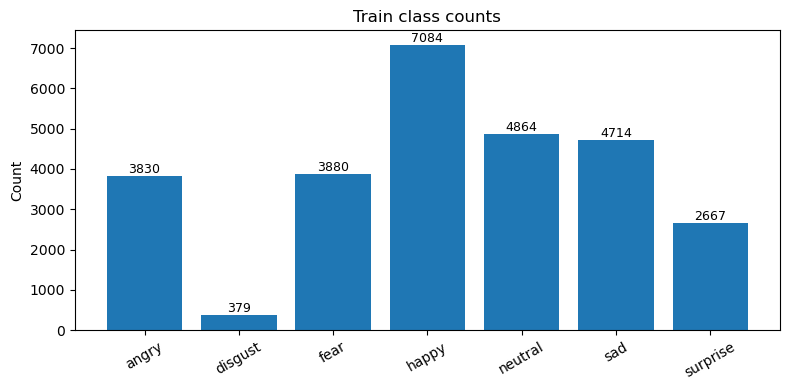

train: {'angry': 3830, 'disgust': 379, 'fear': 3880, 'happy': 7084, 'neutral': 4864, 'sad': 4714, 'surprise': 2667}


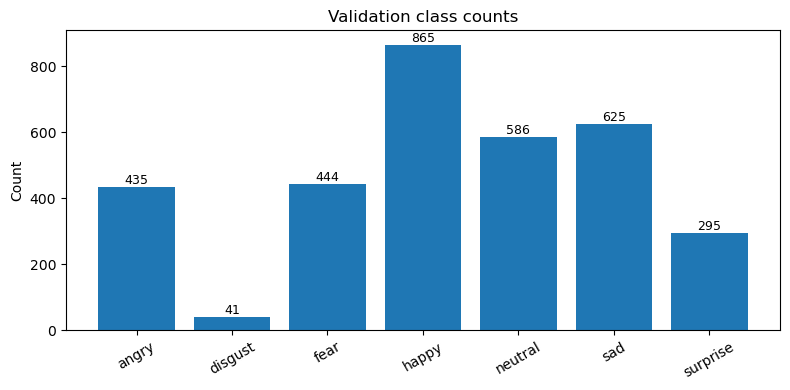

val: {'angry': 435, 'disgust': 41, 'fear': 444, 'happy': 865, 'neutral': 586, 'sad': 625, 'surprise': 295}


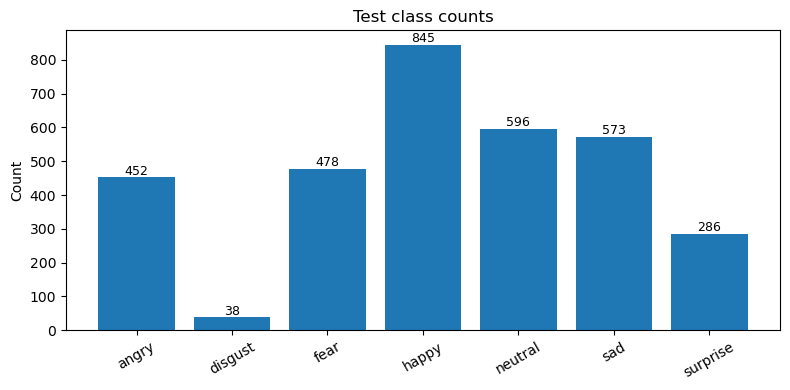

test: {'angry': 452, 'disgust': 38, 'fear': 478, 'happy': 845, 'neutral': 596, 'sad': 573, 'surprise': 286}


In [13]:
from collections import Counter

def plot_split_counts(root, title):
    ds = ImageFolder(root)
    counts = Counter(ds.targets)
    names = [ds.classes[i] for i in range(len(ds.classes))]
    vals = [counts[i] for i in range(len(ds.classes))]

    fig, ax = plt.subplots(figsize=(8, 4))
    ax.bar(names, vals)
    ax.set_title(title)
    ax.set_ylabel("Count")
    ax.tick_params(axis="x", rotation=30)
    for i, v in enumerate(vals):
        ax.text(i, v + max(vals)*0.01, str(v), ha="center", fontsize=9)
    plt.tight_layout()
    plt.show()
    return dict(zip(names, vals))

print("train:", plot_split_counts(CLEAN_DIR / "train", "Train class counts"))
print("val:", plot_split_counts(CLEAN_DIR / "validation", "Validation class counts"))
print("test:", plot_split_counts(CLEAN_DIR / "test", "Test class counts"))

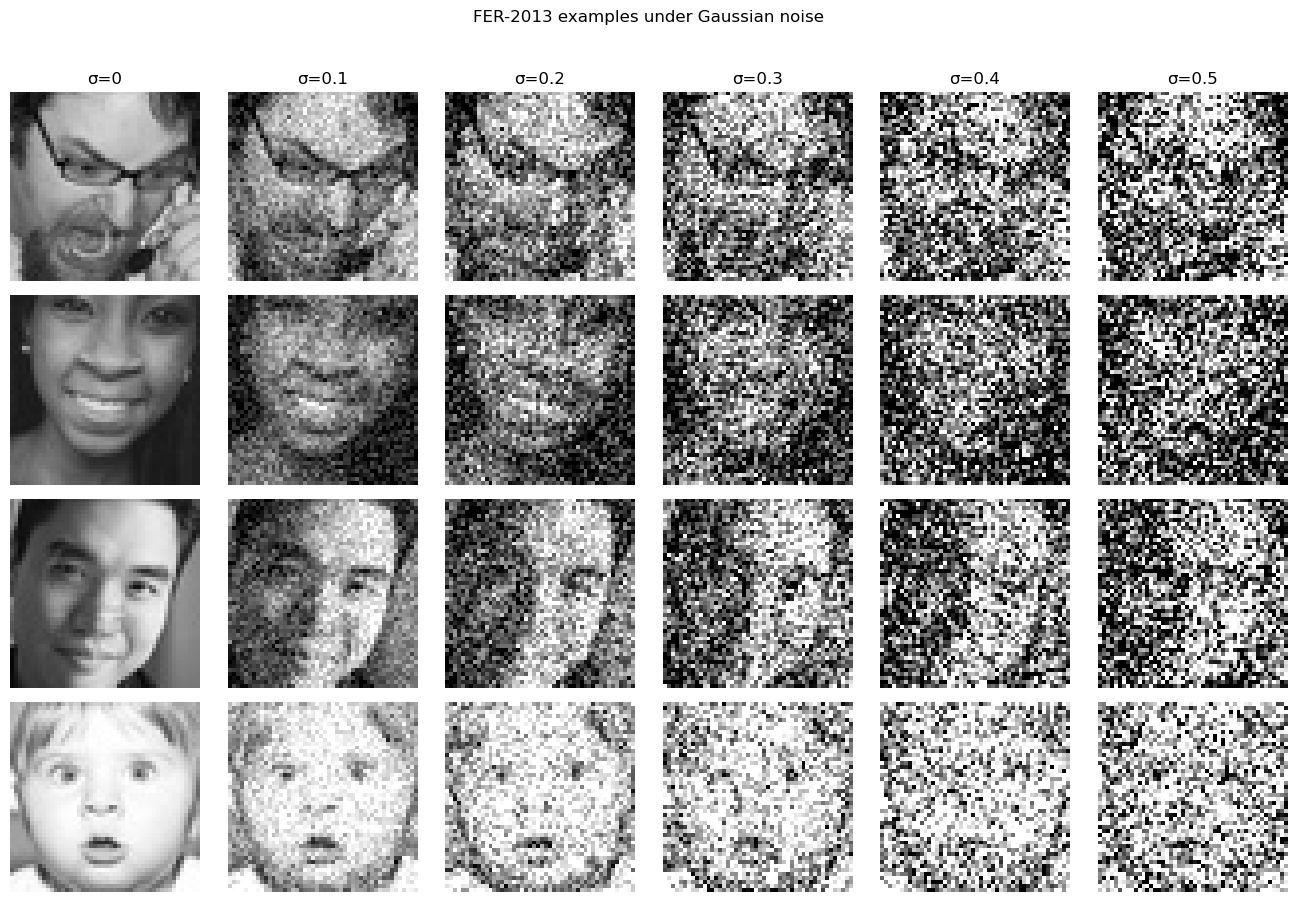

In [14]:
def show_noise_examples(n_images=4, sigmas=NOISE_LEVELS):
    raw = ImageFolder(CLEAN_DIR / "test")
    idxs = np.linspace(0, len(raw) - 1, n_images, dtype=int)
    rng = np.random.default_rng(0)

    fig, axes = plt.subplots(n_images, len(sigmas), figsize=(2.2*len(sigmas), 2.2*n_images))
    if n_images == 1:
        axes = np.expand_dims(axes, 0)

    for r, idx in enumerate(idxs):
        img, label = raw[idx]
        arr = np.asarray(img.convert("L"), dtype=np.float32) / 255.0
        for c, sigma in enumerate(sigmas):
            if sigma == 0:
                shown = arr
            else:
                shown = np.clip(arr + rng.normal(0, sigma, arr.shape).astype(np.float32), 0, 1)
            axes[r, c].imshow(shown, cmap="gray", vmin=0, vmax=1)
            axes[r, c].axis("off")
            if r == 0:
                axes[r, c].set_title(f"σ={sigma:g}")
            if c == 0:
                axes[r, c].set_ylabel(raw.classes[label], rotation=90, fontsize=9)

    fig.suptitle("FER-2013 examples under Gaussian noise", y=1.02)
    plt.tight_layout()
    fig.savefig(OUT_DIR / "vit_noise_examples.png", dpi=200, bbox_inches="tight")
    plt.show()

show_noise_examples()

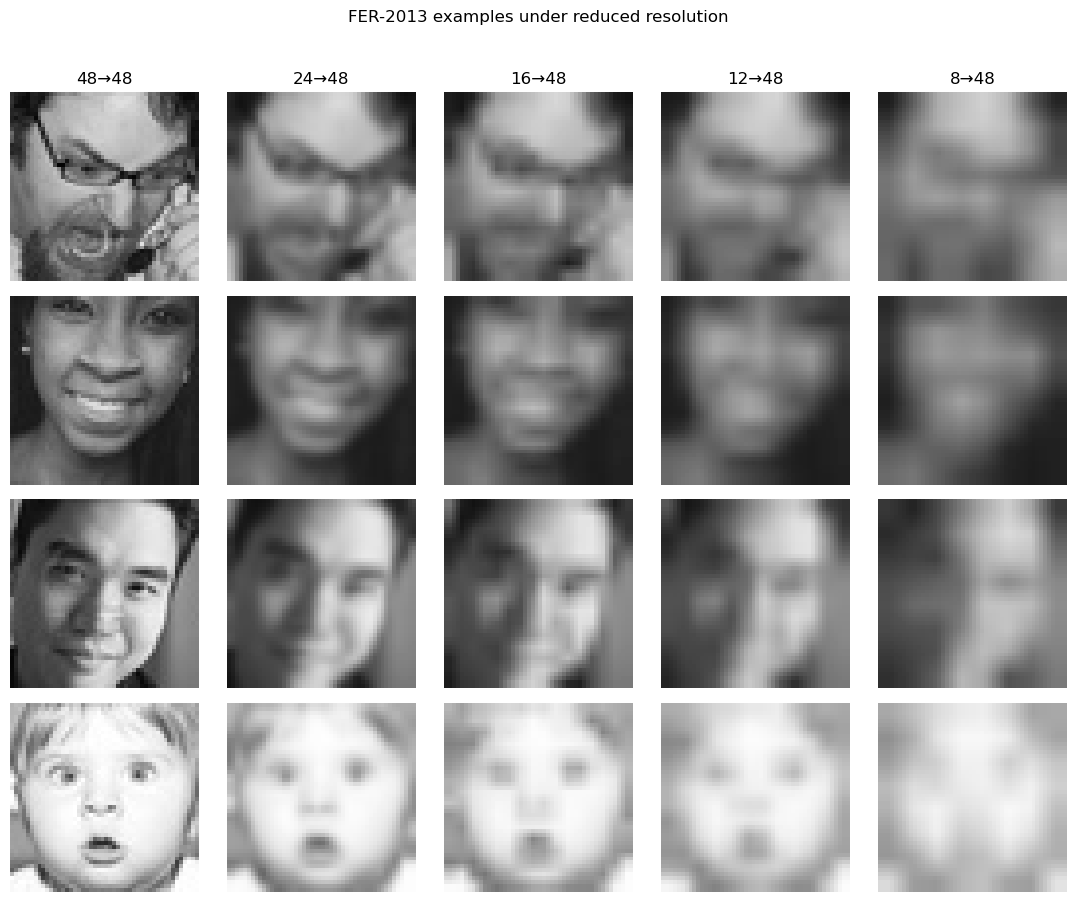

In [15]:
from PIL import Image as PILImage

RES_LEVELS = (48, 24, 16, 12, 8)   # downsample to s×s, then back to 48×48

def reduce_resolution_pil(img_gray_01, size, out_size=48):
    u8 = (np.clip(img_gray_01, 0, 1) * 255).astype(np.uint8)
    pil = PILImage.fromarray(u8, mode="L")
    small = pil.resize((size, size), resample=PILImage.Resampling.BILINEAR)
    back = small.resize((out_size, out_size), resample=PILImage.Resampling.BILINEAR)
    return np.asarray(back, dtype=np.float32) / 255.0

def show_resolution_examples(n_images=4, sizes=RES_LEVELS):
    raw = ImageFolder(CLEAN_DIR / "test")
    idxs = np.linspace(0, len(raw) - 1, n_images, dtype=int)

    fig, axes = plt.subplots(n_images, len(sizes), figsize=(2.2*len(sizes), 2.2*n_images))
    if n_images == 1:
        axes = np.expand_dims(axes, 0)

    for r, idx in enumerate(idxs):
        img, label = raw[idx]
        arr = np.asarray(img.convert("L"), dtype=np.float32) / 255.0
        for c, s in enumerate(sizes):
            shown = reduce_resolution_pil(arr, size=s)
            axes[r, c].imshow(shown, cmap="gray", vmin=0, vmax=1)
            axes[r, c].axis("off")
            if r == 0:
                axes[r, c].set_title(f"{s}→48")
            if c == 0:
                axes[r, c].set_ylabel(raw.classes[label], rotation=90, fontsize=9)

    fig.suptitle("FER-2013 examples under reduced resolution", y=1.02)
    plt.tight_layout()
    fig.savefig(OUT_DIR / "vit_resolution_examples.png", dpi=200, bbox_inches="tight")
    plt.show()

show_resolution_examples()

In [16]:
#ViT stress testing
class DegradedFERViTDataset(Dataset):
    """
    Apply one fixed degradation to every image, then ViT-preprocess.
    mode='noise' uses sigma; mode='resolution' uses size s (down then up to 48).
    """
    def __init__(self, root, processor, mode="noise", sigma=0.0, size=48, seed=123):
        self.base = ImageFolder(root)
        self.processor = processor
        self.mode = mode
        self.sigma = sigma
        self.size = size
        self.rng = np.random.default_rng(seed)

    def __len__(self):
        return len(self.base)

    def __getitem__(self, idx):
        img, label = self.base[idx]
        arr = np.asarray(img.convert("L"), dtype=np.float32) / 255.0

        if self.mode == "noise" and self.sigma > 0:
            arr = np.clip(arr + self.rng.normal(0, self.sigma, arr.shape).astype(np.float32), 0, 1)
        elif self.mode == "resolution":
            arr = reduce_resolution_pil(arr, size=self.size, out_size=48)

        arr3 = np.stack([arr, arr, arr], axis=-1)
        arr3 = (arr3 * 255.0).round().astype(np.uint8)
        pil_rgb = Image.fromarray(arr3, mode="RGB")
        pv = self.processor(images=pil_rgb, return_tensors="pt")["pixel_values"].squeeze(0)
        return pv, label


def eval_loader(model, loader):
    _, acc, f1, _, _ = run_epoch(model, loader)
    return acc, f1


def sweep_noise(model, name, sigmas=NOISE_LEVELS, split="test"):
    # clean reference
    clean_loader = DataLoader(
        DegradedFERViTDataset(CLEAN_DIR / split, processor, mode="noise", sigma=0.0),
        batch_size=BATCH_SIZE, shuffle=False
    )
    clean_acc, clean_f1 = eval_loader(model, clean_loader)

    rows = []
    print(f"\n=== {name} noise sweep ({split}) | clean acc={clean_acc:.4f} ===")
    for sigma in sigmas:
        loader = DataLoader(
            DegradedFERViTDataset(CLEAN_DIR / split, processor, mode="noise", sigma=sigma, seed=123),
            batch_size=BATCH_SIZE, shuffle=False
        )
        acc, f1 = eval_loader(model, loader)
        rel = acc / clean_acc if clean_acc > 0 else np.nan
        pp = 100 * (clean_acc - acc)
        rows.append({"sigma": sigma, "acc": acc, "f1": f1, "pp_loss": pp, "relative": rel})
        print(f"sigma={sigma:.1f} | acc={acc:.4f} f1={f1:.4f} pp_loss={pp:.2f} relative={rel:.4f}")
    return clean_acc, rows


def sweep_resolution(model, name, sizes=RES_LEVELS, split="test"):
    clean_loader = DataLoader(
        DegradedFERViTDataset(CLEAN_DIR / split, processor, mode="resolution", size=48),
        batch_size=BATCH_SIZE, shuffle=False
    )
    clean_acc, clean_f1 = eval_loader(model, clean_loader)

    rows = []
    print(f"\n=== {name} resolution sweep ({split}) | clean acc={clean_acc:.4f} ===")
    for s in sizes:
        loader = DataLoader(
            DegradedFERViTDataset(CLEAN_DIR / split, processor, mode="resolution", size=s),
            batch_size=BATCH_SIZE, shuffle=False
        )
        acc, f1 = eval_loader(model, loader)
        rel = acc / clean_acc if clean_acc > 0 else np.nan
        pp = 100 * (clean_acc - acc)
        rows.append({"size": s, "acc": acc, "f1": f1, "pp_loss": pp, "relative": rel})
        print(f"size={s:2d}→48 | acc={acc:.4f} f1={f1:.4f} pp_loss={pp:.2f} relative={rel:.4f}")
    return clean_acc, rows

In [17]:
clean_acc_c, noise_rows_c = sweep_noise(model_clean, "ViT-clean-train")
clean_acc_n, noise_rows_n = sweep_noise(model_noise, "ViT-noise-aug")
_, res_rows_c = sweep_resolution(model_clean, "ViT-clean-train")
_, res_rows_n = sweep_resolution(model_noise, "ViT-noise-aug")


=== ViT-clean-train noise sweep (test) | clean acc=0.6848 ===


sigma=0.0 | acc=0.6848 f1=0.6228 pp_loss=0.00 relative=1.0000


sigma=0.1 | acc=0.3859 f1=0.3546 pp_loss=29.90 relative=0.5634


sigma=0.2 | acc=0.2240 f1=0.1480 pp_loss=46.08 relative=0.3271


sigma=0.3 | acc=0.1998 f1=0.1184 pp_loss=48.50 relative=0.2918


sigma=0.4 | acc=0.2148 f1=0.1182 pp_loss=47.00 relative=0.3137


... (16 outputs left out)

size=24→48 | acc=0.5557 f1=0.4841 pp_loss=11.29 relative=0.8311


size=16→48 | acc=0.4789 f1=0.3856 pp_loss=18.97 relative=0.7162


size=12→48 | acc=0.3479 f1=0.2830 pp_loss=32.07 relative=0.5204


size= 8→48 | acc=0.2537 f1=0.2020 pp_loss=41.49 relative=0.3794


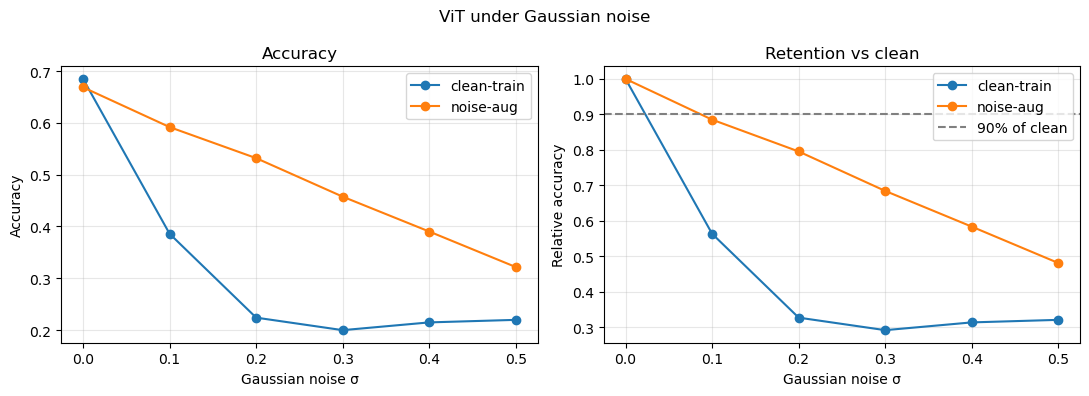

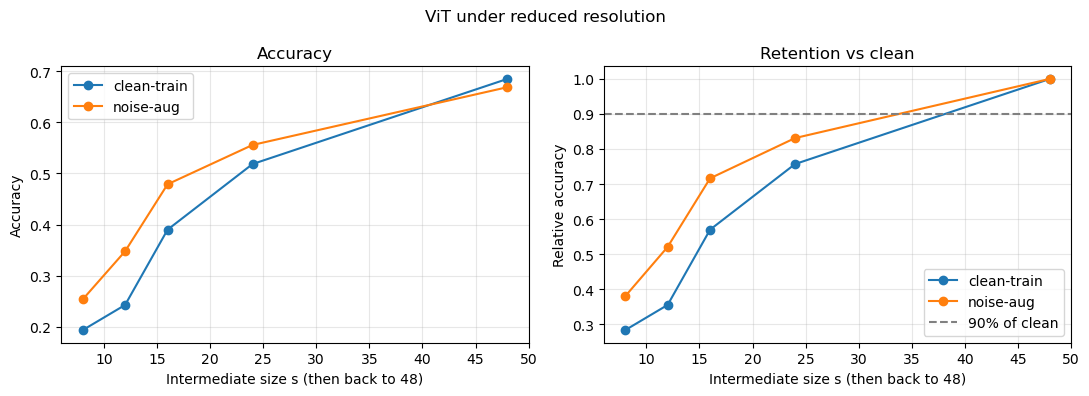

In [18]:
def plot_two_sweeps(rows_a, rows_b, key, label_a, label_b, xlabel, title, save_name):
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))

    xa = [r[key] for r in rows_a]
    xb = [r[key] for r in rows_b]

    axes[0].plot(xa, [r["acc"] for r in rows_a], marker="o", label=label_a)
    axes[0].plot(xb, [r["acc"] for r in rows_b], marker="o", label=label_b)
    axes[0].set_xlabel(xlabel)
    axes[0].set_ylabel("Accuracy")
    axes[0].set_title("Accuracy")
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)

    axes[1].plot(xa, [r["relative"] for r in rows_a], marker="o", label=label_a)
    axes[1].plot(xb, [r["relative"] for r in rows_b], marker="o", label=label_b)
    axes[1].axhline(0.90, color="gray", ls="--", label="90% of clean")
    axes[1].set_xlabel(xlabel)
    axes[1].set_ylabel("Relative accuracy")
    axes[1].set_title("Retention vs clean")
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)

    fig.suptitle(title)
    plt.tight_layout()
    fig.savefig(OUT_DIR / save_name, dpi=200, bbox_inches="tight")
    plt.show()

plot_two_sweeps(
    noise_rows_c, noise_rows_n, "sigma",
    "clean-train", "noise-aug",
    "Gaussian noise σ",
    "ViT under Gaussian noise",
    "vit_noise_sweep.png",
)

plot_two_sweeps(
    res_rows_c, res_rows_n, "size",
    "clean-train", "noise-aug",
    "Intermediate size s (then back to 48)",
    "ViT under reduced resolution",
    "vit_resolution_sweep.png",
)

In [19]:
def first_below_90(rows, key):
    for r in rows:
        if r["relative"] < 0.90:
            return r[key], r["relative"], r["acc"]
    return None, None, None

for name, rows, key in [
    ("ViT-clean noise", noise_rows_c, "sigma"),
    ("ViT-noise-aug noise", noise_rows_n, "sigma"),
    ("ViT-clean resolution", res_rows_c, "size"),
    ("ViT-noise-aug resolution", res_rows_n, "size"),
]:
    level, rel, acc = first_below_90(rows, key)
    print(f"{name}: first <90% retention at {key}={level} (rel={rel}, acc={acc})")

ViT-clean noise: first <90% retention at sigma=0.1 (rel=0.563449508489723, acc=0.38586291309669524)
ViT-noise-aug noise: first <90% retention at sigma=0.1 (rel=0.8851258581235698, acc=0.5917992656058751)
ViT-clean resolution: first <90% retention at size=24 (rel=0.7569258266309205, acc=0.518359853121175)
ViT-noise-aug resolution: first <90% retention at size=24 (rel=0.8311212814645309, acc=0.5556915544675642)
